# Token withholding optimization: hard-zero metrics

Six models with **1, 2, 4, 6, 8, or 10 included neighbor tokens**, sharing the 10-neighbor input design, are compared across the same 19 Breast Xenium slices. Predictions are reused. Rerun metrics use **hard zeroing**, replacing probability scaling, with the original per-cell-type target removal sweep (1%, 2%, 5%, 10%, 20%, 30%, 40%, 50%) and minimum removal probability 0.5. Whole cell–gene entries selected for removal are set to zero; probability scaling is not applied. Whole-gene removals and the probability floor can make achieved removal differ from the target; those values are saved and plotted.

Prior normalization, labels, clustering, random seeds, coordinate settings, sampling, and reference settings are replayed from each original saved config. These are full-cell evaluations, with no additional ≥10-count/≥5-gene QC filter introduced. Output metrics, frozen configs/evaluator code, and job manifests are saved in a new directory; existing probability-scaled results and input matrices remain unchanged.

The notebook reads only tasks with a validated hard-zero completion marker. While jobs are pending, status tables update and plots show waiting messages. Plot curves use matched slice cohorts across **all six** token settings for each metric/fraction, preventing a changing slice mix from driving a token trend.

**Plot cohort:** only the eight sections in `ResponsivenessQueryNativeMarkers.ipynb`: B1_1, B1_2, B1_3, B5, B12, B10, B17, B9. Metric tasks still cover all 19 sections; both curve panels and their matched-slice aggregation use this eight-section subset. The default target remains 0.5.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
RUN = Path("/home/jwinchel/Syndri/context_analysis/results/token_withholding_zero_20261026_112132")
if str(RUN) not in sys.path:
    sys.path.insert(0, str(RUN))
from token_zero_curve_helpers import collect_metrics, plot_curves, NON_METRICS, REFERENCE_METRICS
DESIGN = json.loads((RUN / "design.json").read_text())
TOKEN_LEVELS = DESIGN["tokens"]
# Same eight sections as ResponsivenessQueryNativeMarkers.ipynb.
PLOT_SLICE_DESIGN = Path("/home/jwinchel/Syndri/context_analysis/results/query_native_marker_responsiveness_20261020_115220/design.json")
plot_slice_design = json.loads(PLOT_SLICE_DESIGN.read_text())
PLOT_SLICES = [entry["slice"] for entry in plot_slice_design["slices"]]
PLOT_SLICE_LABELS = [entry["label"] for entry in plot_slice_design["slices"]]
print("Plotted slices:", ", ".join(PLOT_SLICE_LABELS))
PLOT_FRACTIONS = [0.5]  # Change e.g. to [0.1, 0.3, 0.5] or DESIGN["target_removed_fractions"].
REQUIRE_SHARED_SLICES = True
MIN_SLICES_PER_POINT = 3
if not set(PLOT_FRACTIONS).issubset(set(DESIGN["target_removed_fractions"])):
    raise ValueError("Choose fractions from the evaluated sweep")
print("Hard-zero results:", RUN)


Plotted slices: B1_1, B1_2, B1_3, B5, B12, B10, B17, B9
Hard-zero results: /home/jwinchel/Syndri/context_analysis/results/token_withholding_zero_20261026_112132


## Metric completion and paired slice support

Each family has 114 tasks (6 token settings × 19 slices); every task evaluates raw counts and all eight removal fractions. A completion marker requires successful evaluation and validation, so partial CSVs from a failed task are excluded. The reference family saves all-cell-type cosine similarity and gene-variance concordance, with per-cell-type and per-gene tables. The previous T-cell jobs were superseded and their outputs are not read by this notebook.


In [2]:
status, non_tcell_rows, reference_slice_rows = collect_metrics(RUN)
# Filtering applies to the plotted data only; all task outputs remain available.
all_status = status.copy()
missing_slices = set(PLOT_SLICES) - set(all_status["slice"])
if missing_slices:
    raise ValueError(f"Selected slices missing from metric manifests: {sorted(missing_slices)}")
status = status.loc[status["slice"].isin(PLOT_SLICES)].copy()
if not non_tcell_rows.empty:
    non_tcell_rows = non_tcell_rows.loc[non_tcell_rows["slice"].isin(PLOT_SLICES)].copy()
if not reference_slice_rows.empty:
    reference_slice_rows = reference_slice_rows.loc[reference_slice_rows["slice"].isin(PLOT_SLICES)].copy()
pd.DataFrame({"slice": PLOT_SLICES, "label": PLOT_SLICE_LABELS}).to_csv(
    RUN / "plotted_responsiveness_slices.csv", index=False)
completion = status.groupby(["family", "tokens"], sort=False).agg(expected=("slice", "size"), completed=("complete", "sum"))
display(completion)
print(f"{int(status.complete.sum())}/{len(status)} validated tasks for the selected eight slices")
if (RUN / "jobs.json").exists():
    display(pd.DataFrame(json.loads((RUN / "jobs.json").read_text())).T)


expected  completed
family    tokens                     
non_tcell 1              8          8
          2              8          8
          4              8          8
          6              8          8
          8              8          8
          10             8          8
reference 1              8          8
          2              8          8
          4              8          8
          6              8          8
          8              8          8
          10             8          8

96/96 validated tasks for the selected eight slices


,job_id,tasks,cpus,memory,max_concurrent,status,dependency
non_tcell,126937,114,4,48G,4,NaN,NaN
reference,126953,114,4,32G,4,NaN,NaN
superseded_tcell,126938,114,4,48G,2,canceled at user request; use reference metrics,NaN
superseded_plots,126939,1,4,12G,NaN,canceled; replaced by new dependency,afterany:126937:126938
plots,126954,1,4,12G,NaN,NaN,afterany:126937:126953


## Cell-type separation and count curves

X is included neighbor-token count. For the selected removal fractions, lines are **median across matched slices**, with slice IQR ribbons (not confidence intervals). Raw is shown as a dashed baseline. The default 50% condition matches the cell-switch analysis; `PLOT_FRACTIONS` selects other evaluated targets. Higher is conventionally better for silhouette, Calinski–Harabasz, Leiden NMI/ARI; lower for Davies–Bouldin. Count metrics describe changes rather than an accuracy target.

A curve is omitted until at least three slices have finite results at **every token level** for that metric/fraction. CSVs record the exact contributing slice values and support counts. Adjacent token settings are connected only to show the tested sequence.


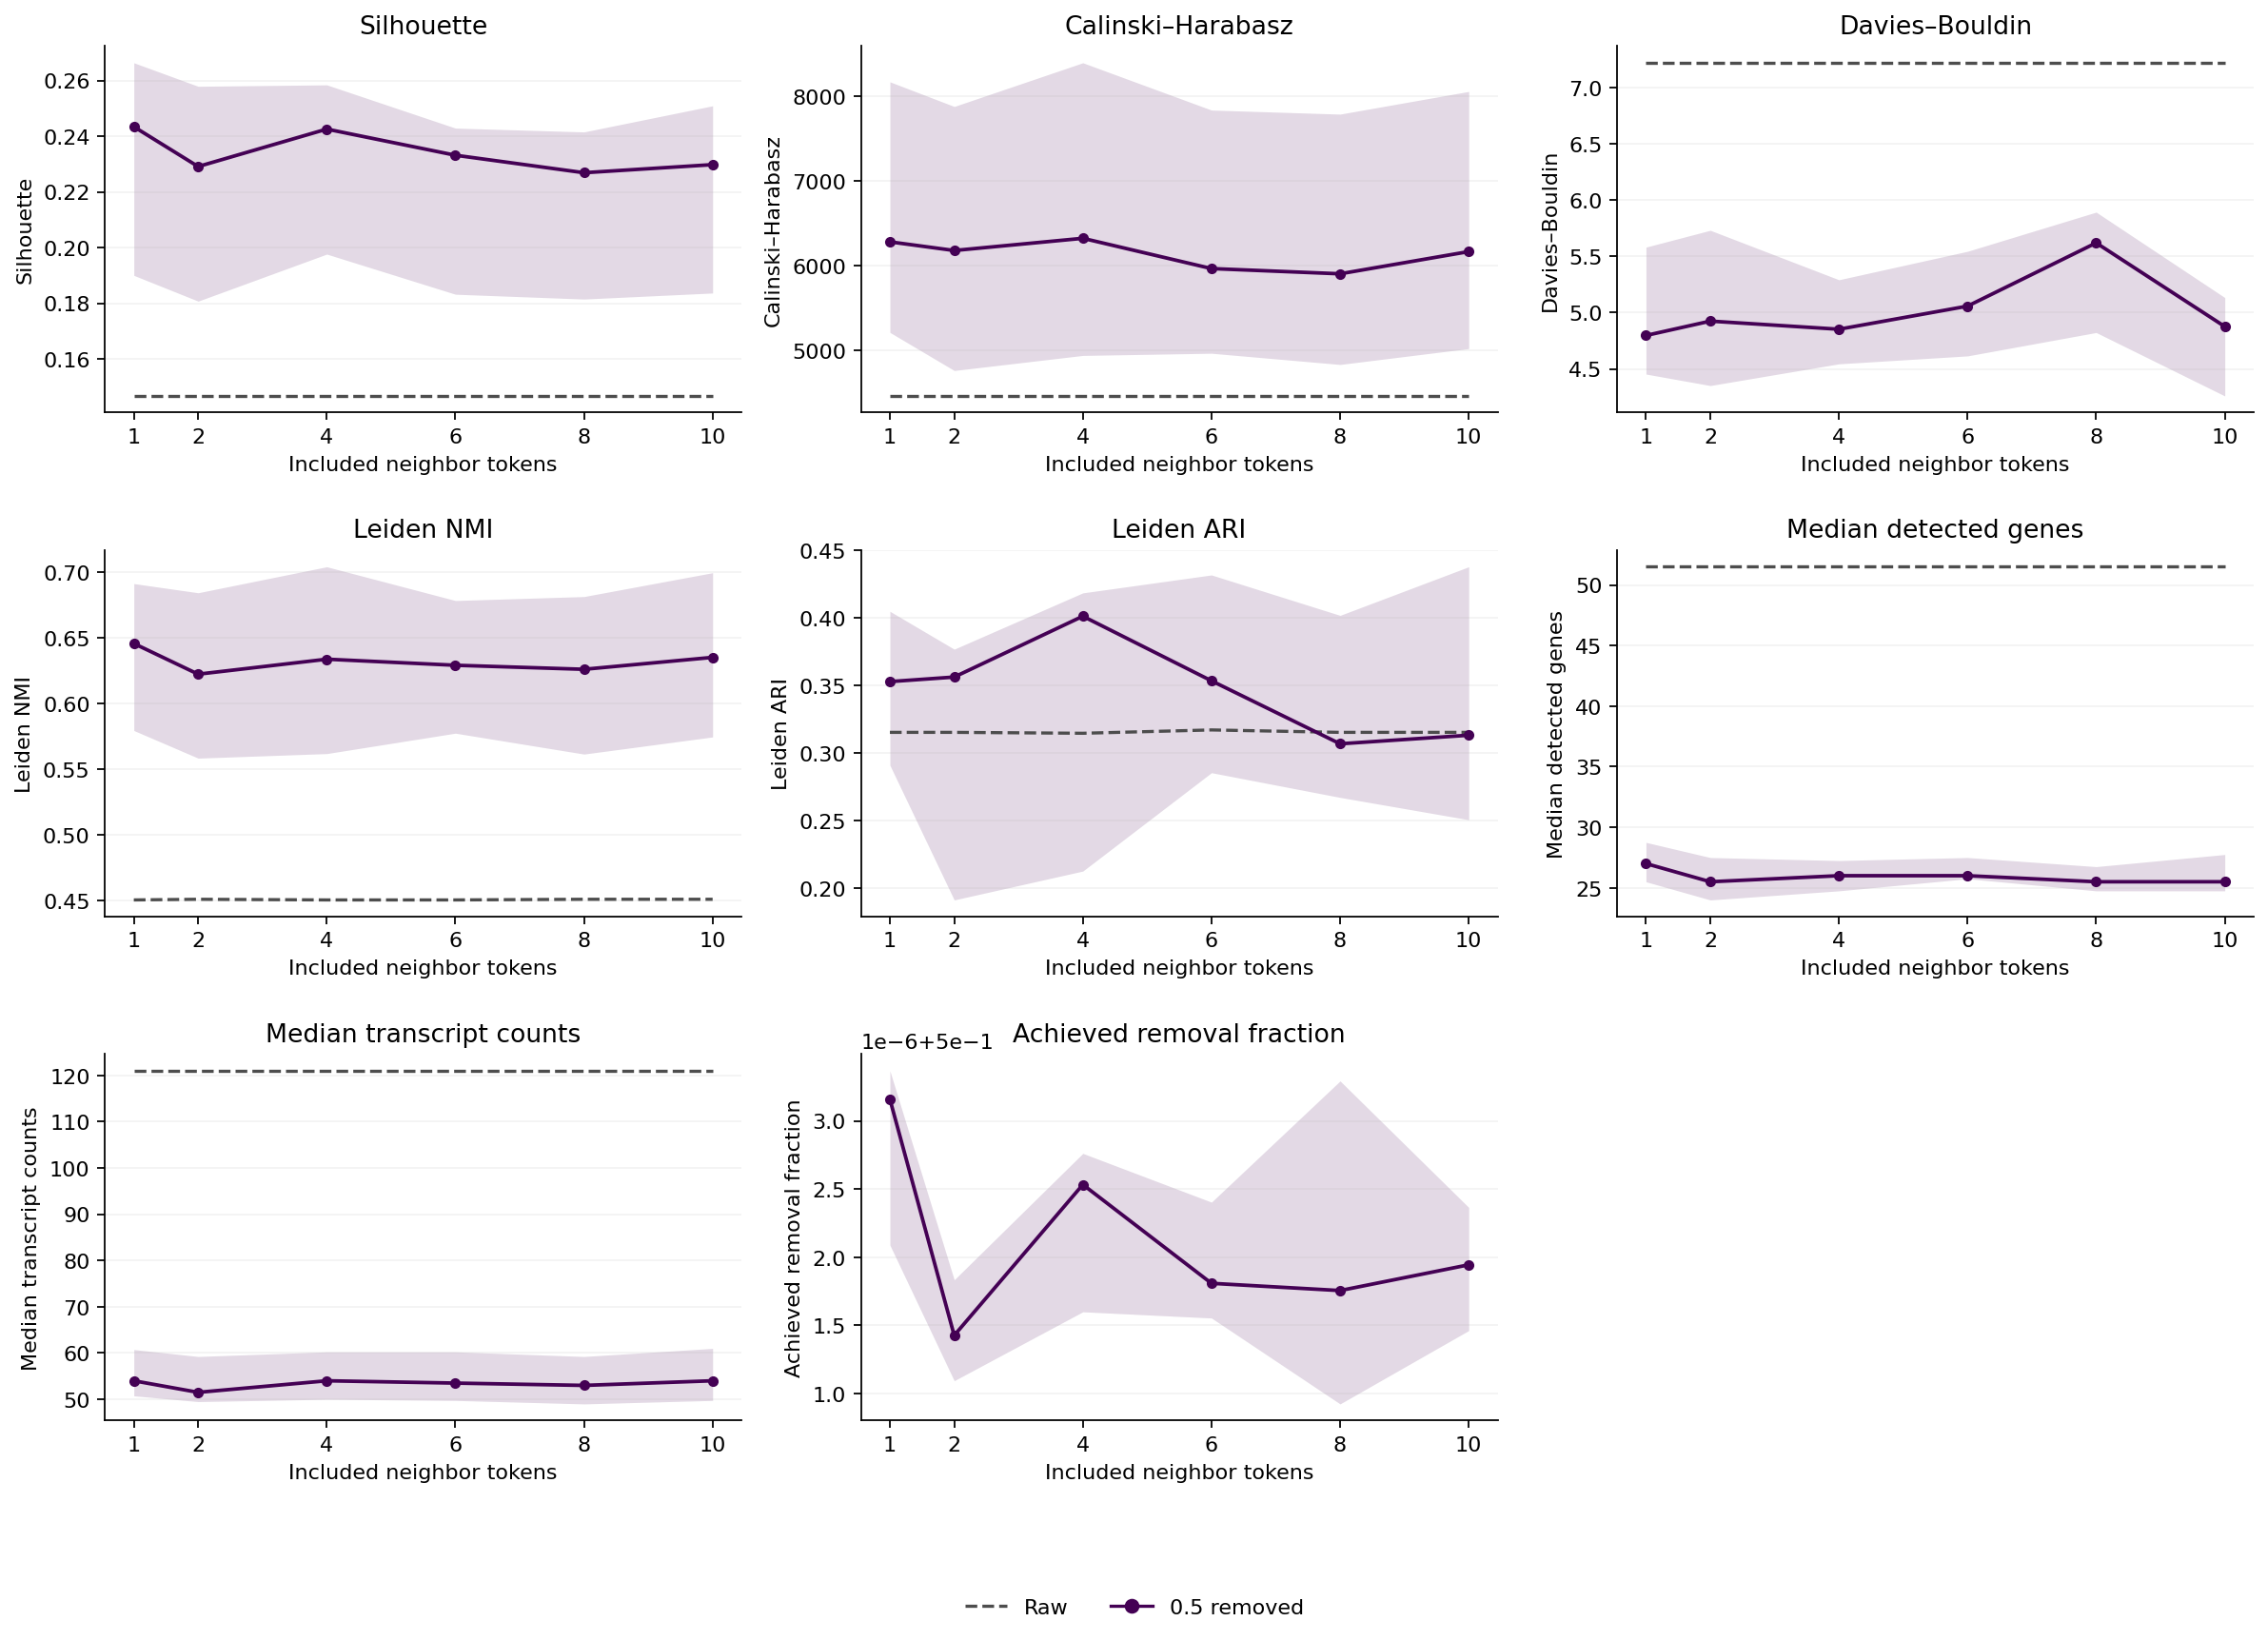

,metric,fraction,tokens,median,q25,q75,n_slices
0,achieved_removed_fraction,0.01,1,0.010019,0.010013,0.010036,8
1,achieved_removed_fraction,0.01,2,0.010031,0.010021,0.010040,8
2,achieved_removed_fraction,0.01,4,0.010018,0.010010,0.010025,8
3,achieved_removed_fraction,0.01,6,0.010015,0.010009,0.010033,8
4,achieved_removed_fraction,0.01,8,0.010018,0.010013,0.010029,8
...,...,...,...,...,...,...,...
421,silhouette_score,0.50,2,0.229090,0.180742,0.257914,8
422,silhouette_score,0.50,4,0.242535,0.197638,0.258427,8
423,silhouette_score,0.50,6,0.233149,0.183221,0.242899,8
424,silhouette_score,0.50,8,0.226867,0.181492,0.241523,8


In [3]:
if non_tcell_rows.empty:
    non_tcell_long = pd.DataFrame()
else:
    non_tcell_long = non_tcell_rows.melt(
        id_vars=["tokens", "slice", "fraction"],
        value_vars=list(NON_METRICS), var_name="metric", value_name="value")
non_tcell_curve_summary = plot_curves(
    RUN, non_tcell_long, NON_METRICS, PLOT_FRACTIONS, TOKEN_LEVELS,
    "hard_zero_token_separation_count_curves_responsiveness_slices", paired=REQUIRE_SHARED_SLICES,
    min_slices=MIN_SLICES_PER_POINT)
if not non_tcell_curve_summary.empty:
    display(non_tcell_curve_summary)


## All-cell-type reference cosine and gene-variance preservation

**Cosine:** use the existing all-cell-type pseudobulk cosine definition. Sum raw/corrected counts by annotated cell type; restrict to shared genes, normalize each pseudobulk to 10,000 and log1p, then calculate cosine to the matching reference type. Use reference **X**, matching the existing all-cell-type cosine metric, and at least one cell in each matched type. Compute the **arithmetic mean across eligible cell types**, giving types equal weight within each slice.

**Gene variance:** match `VariancePreservation.ipynb` for Breast Xenium. Use the reference’s **SoupX** layer, at least **50 spatial and 50 reference cells** per type, and genes detected in ≥5% of reference cells with positive reference variance. Select hard-zero cutoffs on the full spatial panel. Normalize spatial cells over that full panel to 10,000 and log1p, then subset to shared genes; reference normalization uses shared genes, as in that notebook. Calculate sparse float32 population variance per gene within each type and Spearman correlation of spatial versus reference gene variances. The slice score is the **median correlation across eligible types**, matching the variance notebook. Constant variance vectors and insufficient support remain missing.

For each metric, slice and target fraction, retain the same finite cell types across **all six token settings** before taking the mean cosine or median variance rho. Then plot the median and IQR across slices present at every token level. Thus the curves cannot improve simply by dropping a difficult type in one model. This matched type coverage is exported alongside all per-type measurements; reference cell types are not weighted by their abundance. Reference curves evaluate every original removal target; `PLOT_FRACTIONS` controls display.

Files per reference task: `reference_cosine_similarity.csv`, `gene_variance_concordance.csv`, `gene_variance_values.csv.gz`, `slice_reference_metrics.csv`, and full settings. The X-versus-SoupX distinction preserves the existing definitions of the two requested metrics.


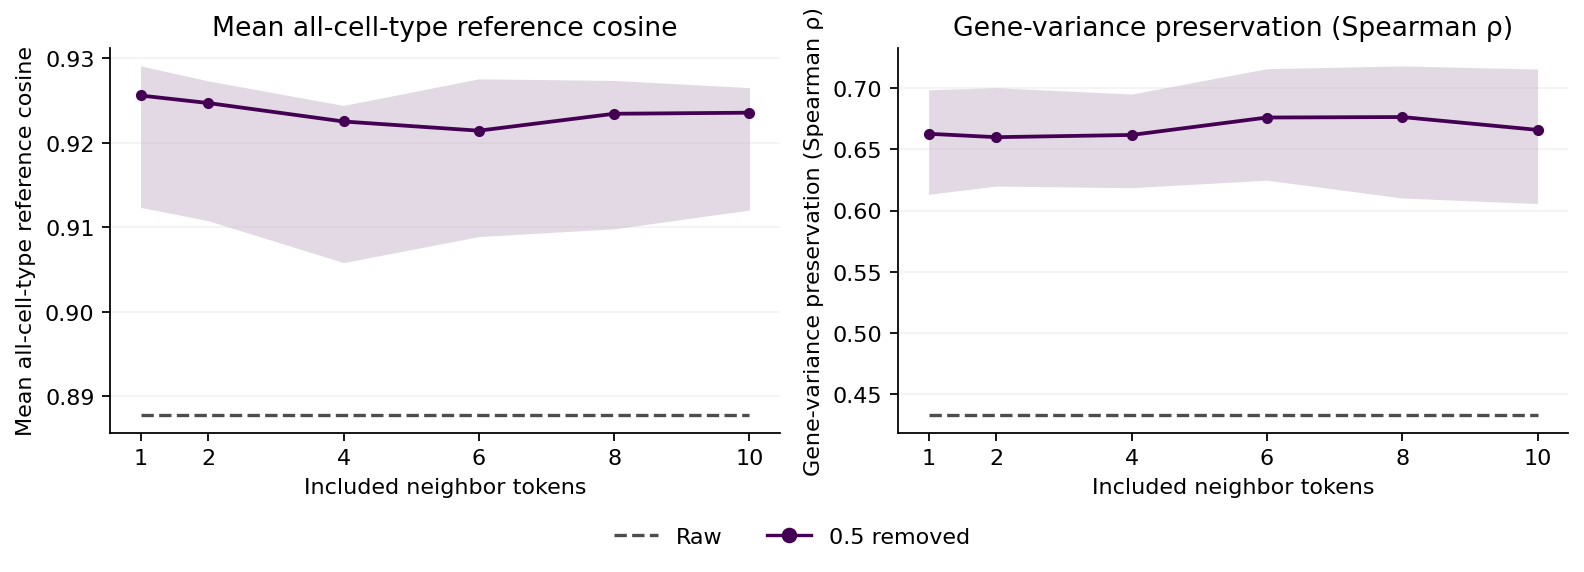

,metric,fraction,tokens,median,q25,q75,n_slices
0,cosine_similarity,0.0,1,0.887787,0.881255,0.907524,8
1,cosine_similarity,0.0,2,0.887787,0.881255,0.907524,8
2,cosine_similarity,0.0,4,0.887787,0.881255,0.907524,8
3,cosine_similarity,0.0,6,0.887787,0.881255,0.907524,8
4,cosine_similarity,0.0,8,0.887787,0.881255,0.907524,8
...,...,...,...,...,...,...,...
103,gene_variance_spearman,0.5,2,0.659970,0.619987,0.700437,8
104,gene_variance_spearman,0.5,4,0.661800,0.618683,0.695236,8
105,gene_variance_spearman,0.5,6,0.676047,0.624815,0.715956,8
106,gene_variance_spearman,0.5,8,0.676435,0.610252,0.718227,8


In [4]:
reference_curve_summary = plot_curves(RUN, reference_slice_rows, REFERENCE_METRICS, PLOT_FRACTIONS,
    TOKEN_LEVELS, "hard_zero_token_reference_curves_responsiveness_slices", paired=REQUIRE_SHARED_SLICES,
    min_slices=MIN_SLICES_PER_POINT)
if not reference_curve_summary.empty:
    display(reference_curve_summary)


## Score token settings on three equally weighted axes

Use the selected eight responsiveness sections and **target fraction 0.5**. Only tested settings **1, 2, 4, 6, 8, 10** receive scores; do not interpolate 3, 5, 7, or 9. Require the same sections with all five metrics available at every setting.

For each metric within each section, rank the six settings (all five metrics are higher-is-better), with average ranks for ties. Convert ranks to **0–100**: `100 × (rank − 1)/5`, where 0 is worst and 100 best among tested settings. Compute:

- **Separation:** mean of the ARI, NMI, and silhouette rank scores.
- **Reference similarity:** all-cell-type cosine rank score (the slice value is the mean over eligible types).
- **Variance preservation:** gene-variance Spearman rank score (the slice value is the median over eligible types).

Average each axis equally over sections. **Overall** is the equally weighted mean of the three axes, so separation's three metrics together have one-third weight. Export raw values, metric ranks, per-section axis scores, and aggregate scores. Raw metric medians are displayed for effect-size context. These are relative ranking scores, not percentages of biological accuracy or a significance test; tiny and large metric differences can produce the same rank change. Sections, including the three B1 replicates, receive equal weights.


Scored 6 tested settings on 8 common slices; target=0.5.


,Separation,Reference similarity,Variance preservation,Overall,overall_rank,n_slices
tokens,,,,,,
1,75.8,95.0,38.8,69.9,1,8
2,28.3,62.5,40.0,43.6,5,8
4,65.8,10.0,42.5,39.4,6,8
6,45.0,32.5,77.5,51.7,2,8
8,25.0,47.5,61.2,44.6,4,8
10,60.0,52.5,40.0,50.8,3,8


Raw metric medians across the same slices:


metric,leiden_adjusted_rand_vs_label,leiden_nmi_vs_label,silhouette_score,cosine_similarity,gene_variance_spearman
tokens,,,,,
1,0.3530,0.6458,0.2434,0.9256,0.6628
2,0.3564,0.6223,0.2291,0.9247,0.6600
4,0.4014,0.6338,0.2425,0.9225,0.6618
6,0.3536,0.6292,0.2331,0.9214,0.6760
8,0.3069,0.6261,0.2269,0.9234,0.6764
10,0.3133,0.6352,0.2298,0.9235,0.6659


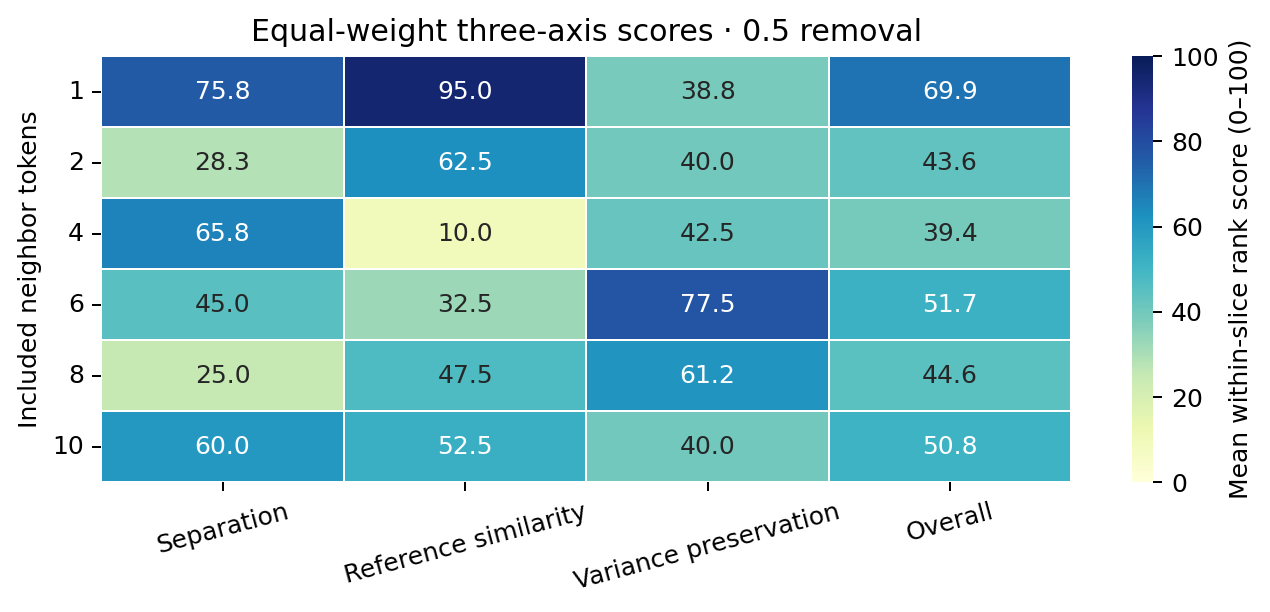

In [5]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SCORE_TARGET_FRACTION = 0.5
SCORE_AXIS_WEIGHTS = {"Separation": 1/3, "Reference similarity": 1/3, "Variance preservation": 1/3}
score_run = Path("/home/jwinchel/Syndri/context_analysis/results/token_withholding_zero_20261026_112132")
score_levels = json.loads((score_run / "design.json").read_text())["tokens"]
score_slices = pd.read_csv(score_run / "plotted_responsiveness_slices.csv")["slice"].tolist()
separation_score_metrics = ["leiden_adjusted_rand_vs_label", "leiden_nmi_vs_label", "silhouette_score"]
reference_score_metrics = ["cosine_similarity", "gene_variance_spearman"]
score_metrics = separation_score_metrics + reference_score_metrics
score_parts = []
for filename, metrics in [
    ("hard_zero_token_separation_count_curves_responsiveness_slices_paired_slice_values.csv", separation_score_metrics),
    ("hard_zero_token_reference_curves_responsiveness_slices_paired_slice_values.csv", reference_score_metrics),
]:
    table = pd.read_csv(score_run / filename)
    score_parts.append(table.loc[np.isclose(table.fraction, SCORE_TARGET_FRACTION)
        & table.metric.isin(metrics) & table["slice"].isin(score_slices),
        ["slice", "tokens", "metric", "value"]])
score_long = pd.concat(score_parts, ignore_index=True)
if score_long.duplicated(["slice", "tokens", "metric"]).any():
    raise ValueError("Duplicate slice/token/metric rows")
score_wide = score_long.pivot(index=["slice", "tokens"], columns="metric", values="value").reindex(columns=score_metrics)
score_wide = score_wide.replace([np.inf, -np.inf], np.nan).dropna()
score_support = score_wide.reset_index().groupby("slice").tokens.agg(lambda v: set(v) == set(score_levels))
score_shared_slices = score_support.index[score_support].tolist()
score_wide = score_wide.loc[score_wide.index.get_level_values("slice").isin(score_shared_slices)].copy()
if not score_shared_slices:
    raise ValueError("No slices with all five metrics at all six token settings")
# For each slice and metric: lowest=0, highest=100; ties use average ranks.
score_ranks = score_wide.groupby(level="slice").rank(method="average", ascending=True)
score_percentiles = 100 * (score_ranks - 1) / (len(score_levels) - 1)
score_axes = pd.DataFrame(index=score_wide.index)
score_axes["Separation"] = score_percentiles[separation_score_metrics].mean(axis=1)
score_axes["Reference similarity"] = score_percentiles["cosine_similarity"]
score_axes["Variance preservation"] = score_percentiles["gene_variance_spearman"]
if not np.isclose(sum(SCORE_AXIS_WEIGHTS.values()), 1):
    raise ValueError("Axis weights must sum to one")
score_axes["Overall"] = sum(score_axes[axis] * weight for axis, weight in SCORE_AXIS_WEIGHTS.items())
# Equal slice weights for each model; separation has one-third total weight,
# rather than getting triple weight for containing three metrics.
token_score_table = score_axes.groupby(level="tokens").mean().reindex(score_levels)
token_score_table["overall_rank"] = token_score_table.Overall.rank(method="min", ascending=False).astype(int)
token_score_table["n_slices"] = len(score_shared_slices)
raw_token_metrics = score_wide.groupby(level="tokens").median().reindex(score_levels)
score_label = f"target{SCORE_TARGET_FRACTION:g}_responsiveness_slices"
score_wide.to_csv(score_run / f"token_score_raw_slice_metrics_{score_label}.csv")
score_percentiles.to_csv(score_run / f"token_score_slice_metric_percentiles_{score_label}.csv")
score_axes.to_csv(score_run / f"token_score_slice_axes_{score_label}.csv")
token_score_table.to_csv(score_run / f"token_axis_scores_{score_label}.csv")
raw_token_metrics.to_csv(score_run / f"token_score_raw_metric_medians_{score_label}.csv")
print(f"Scored {len(score_levels)} tested settings on {len(score_shared_slices)} common slices; target={SCORE_TARGET_FRACTION:g}.")
display(token_score_table.round(1))
print("Raw metric medians across the same slices:")
display(raw_token_metrics.round(4))
fig, ax = plt.subplots(figsize=(7.5, 3.5), dpi=180)
sns.heatmap(token_score_table[[*SCORE_AXIS_WEIGHTS, "Overall"]],
    vmin=0, vmax=100, cmap="YlGnBu", annot=True, fmt=".1f", linewidths=.6,
    cbar_kws={"label":"Mean within-slice rank score (0–100)"}, ax=ax)
ax.set_ylabel("Included neighbor tokens")
ax.set_xlabel("")
ax.tick_params(axis="y", labelrotation=0)
ax.tick_params(axis="x", labelrotation=15)
ax.set_title(f"Equal-weight three-axis scores · {SCORE_TARGET_FRACTION:g} removal")
fig.tight_layout()
for ext in ["png", "pdf"]:
    fig.savefig(score_run / f"token_axis_scores_{score_label}.{ext}", bbox_inches="tight")
plt.show()
